In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn import tree
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_val_score
import joblib

In [67]:
df=pd.read_csv("../MachineLearningAgain/MachineLearningDataSets/VehiclesDataSets/car details v4.csv")
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [68]:
df["Make"].value_counts()

Make
Maruti Suzuki    440
Hyundai          349
Mercedes-Benz    171
Honda            158
Toyota           132
Audi             127
BMW              121
Mahindra         119
Tata              57
Volkswagen        50
Ford              48
Renault           43
Skoda             40
Land Rover        33
Kia               23
Jeep              18
Jaguar            17
MG                17
Nissan            16
Volvo             16
Porsche           15
MINI              11
Datsun             8
Chevrolet          7
Lexus              6
Mitsubishi         4
Ssangyong          3
Rolls-Royce        3
Isuzu              2
Fiat               2
Maserati           1
Ferrari            1
Lamborghini        1
Name: count, dtype: int64

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

## DATA CLEANING

In [70]:
df.drop(columns=["Model","Make"],axis=1,inplace=True)

In [71]:
df.head()

,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [72]:
# OUTLIER VALUES
IQR = df['Price'].quantile(0.75) - df['Price'].quantile(0.25)
lower_limit = df['Price'].quantile(0.25) - 1.5*IQR
upper_limit = df['Price'].quantile(0.75) + 1.5*IQR
df=df[(df['Price'] >= lower_limit) & (df['Price'] <= upper_limit)]

In [73]:
df["Location"].unique()

array(['Pune', 'Ludhiana', 'Lucknow', 'Mangalore', 'Mumbai', 'Coimbatore',
       'Bangalore', 'Delhi', 'Raipur', 'Kanpur', 'Patna', 'Vadodara',
       'Hyderabad', 'Yamunanagar', 'Gurgaon', 'Jaipur', 'Deoghar', 'Agra',
       'Goa', 'Warangal', 'Jalandhar', 'Noida', 'Ahmedabad', 'Mohali',
       'Navi Mumbai', 'Kolkata', 'Zirakpur', 'Nagpur', 'Thane',
       'Faridabad', 'Ranchi', 'Amritsar', 'Chennai', 'Udupi', 'Panvel',
       'Jamshedpur', 'Aurangabad', 'Rudrapur', 'Nashik', 'Varanasi',
       'Salem', 'Dehradun', 'Chandigarh', 'Valsad', 'Haldwani', 'Dharwad',
       'Surat', 'Karnal', 'Panchkula', 'Mysore', 'Rohtak', 'Ambala Cantt',
       'Samastipur', 'Ghaziabad', 'Unnao', 'Purnea', 'Bhubaneswar',
       'Kheda', 'Kollam', 'Meerut', 'Indore', 'Ernakulam', 'Kharar',
       'Mirzapur', 'Bhopal', 'Gorakhpur', 'Guwahati', 'Allahabad',
       'Muzaffurpur', 'Faizabad', 'Kota', 'Pimpri-Chinchwad',
       'Dak. Kannada', 'Ranga Reddy', 'Bulandshahar', 'Roorkee',
       'Siliguri'], dty

In [74]:
top10_list=df["Location"].value_counts()

In [75]:
top10_list

Location
Mumbai              309
Delhi               250
Pune                124
Bangalore           117
Hyderabad            99
                   ... 
Faizabad              1
Pimpri-Chinchwad      1
Rohtak                1
Valsad                1
Siliguri              1
Name: count, Length: 77, dtype: int64

In [76]:
df["Location"]=df["Location"].apply(lambda x:x if x in top10_list else "other")

In [77]:
df.head()

,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [78]:
new_columns_power=df["Max Power"].str.split("@",expand=True)
new_columns_torque=df["Max Torque"].str.split("@",expand=True)

df["max_power_bhp"]=new_columns_power[0]
df["max_power_rpm"]=new_columns_power[1]

df["max_torque_Nm"]=new_columns_torque[0]
df["max_torque_rpm"]=new_columns_torque[1]
df.drop(columns=["Max Power","Max Torque"],axis=1,inplace=True)
df.head()

,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,max_power_bhp,max_power_rpm,max_torque_Nm,max_torque_rpm
0,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,FWD,3990.0,1680.0,1505.0,5.0,35.0,87 bhp,6000 rpm,109 Nm,4500 rpm
1,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,FWD,3995.0,1695.0,1555.0,5.0,42.0,74 bhp,4000 rpm,190 Nm,2000 rpm
2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,FWD,3585.0,1595.0,1550.0,5.0,35.0,79 bhp,6000 rpm,112.7619 Nm,4000 rpm
3,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,FWD,3995.0,1745.0,1510.0,5.0,37.0,82 bhp,6000 rpm,113 Nm,4200 rpm
4,1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,RWD,4735.0,1830.0,1795.0,7.0,55.0,148 bhp,3400 rpm,343 Nm,1400 rpm


In [79]:
items_to_drop=["cc","bhp","rpm","Nm"]
columns_to_fix=["Engine","max_power_bhp","max_power_bhp","max_power_rpm","max_torque_Nm","max_torque_rpm"]
for col in columns_to_fix:
    df[col]=df[col].replace(items_to_drop,"",regex=True)

In [80]:
df.head()

,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,max_power_bhp,max_power_rpm,max_torque_Nm,max_torque_rpm
0,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198,FWD,3990.0,1680.0,1505.0,5.0,35.0,87,6000,109,4500
1,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248,FWD,3995.0,1695.0,1555.0,5.0,42.0,74,4000,190,2000
2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197,FWD,3585.0,1595.0,1550.0,5.0,35.0,79,6000,112.7619,4000
3,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197,FWD,3995.0,1745.0,1510.0,5.0,37.0,82,6000,113,4200
4,1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393,RWD,4735.0,1830.0,1795.0,7.0,55.0,148,3400,343,1400


In [81]:
df.isnull().sum()

Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 75
Drivetrain            131
Length                 59
Width                  59
Height                 59
Seating Capacity       59
Fuel Tank Capacity     96
max_power_bhp          75
max_power_rpm          75
max_torque_Nm          75
max_torque_rpm         75
dtype: int64

In [82]:
df["Engine"]=df["Engine"].astype(float)

In [83]:
problem_columns=["max_power_bhp","max_power_rpm","max_torque_Nm","max_torque_rpm"]

In [84]:
for col in problem_columns:
    df[col]=pd.to_numeric(df[col],errors="coerce")

In [85]:
df[["max_power_bhp","max_power_rpm","max_torque_Nm","max_torque_rpm"]]=df[["max_power_bhp","max_power_rpm","max_torque_Nm","max_torque_rpm"]].astype(float)

In [86]:
df['Price'] = np.log(df['Price'])

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1844 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1844 non-null   float64
 1   Year                1844 non-null   int64  
 2   Kilometer           1844 non-null   int64  
 3   Fuel Type           1844 non-null   object 
 4   Transmission        1844 non-null   object 
 5   Location            1844 non-null   object 
 6   Color               1844 non-null   object 
 7   Owner               1844 non-null   object 
 8   Seller Type         1844 non-null   object 
 9   Engine              1769 non-null   float64
 10  Drivetrain          1713 non-null   object 
 11  Length              1785 non-null   float64
 12  Width               1785 non-null   float64
 13  Height              1785 non-null   float64
 14  Seating Capacity    1785 non-null   float64
 15  Fuel Tank Capacity  1748 non-null   float64
 16  max_power_b

In [88]:
df.describe()

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,max_power_bhp,max_power_rpm,max_torque_Nm,max_torque_rpm
count,1844.000000,1844.000000,1.844000e+03,1769.000000,1785.00000,1785.000000,1785.000000,1785.000000,1748.000000,1769.000000,1765.00000,1769.000000,1769.000000
mean,13.593484,2016.110629,5.701415e+04,1600.895421,4213.99944,1747.309804,1590.350140,5.321569,49.686785,116.632391,4893.76204,220.258998,2720.214811
std,0.780766,3.332491,5.944373e+04,556.984817,411.83685,121.688894,133.349334,0.804771,13.443042,48.982015,1103.63609,119.322111,1218.189833
min,10.799576,1988.000000,7.500000e+01,624.000000,3099.00000,1475.000000,1297.000000,2.000000,15.000000,35.000000,2910.00000,48.000000,150.000000
25%,13.017003,2014.000000,3.300000e+04,1197.000000,3971.00000,1695.000000,1485.000000,5.000000,40.000000,82.000000,4000.00000,114.000000,1750.000000
50%,13.514405,2017.000000,5.300000e+04,1493.000000,4270.00000,1745.000000,1545.000000,5.000000,45.000000,103.000000,5000.00000,195.000000,2000.000000
75%,14.205858,2018.000000,7.300000e+04,1968.000000,4490.00000,1820.000000,1665.000000,5.000000,60.000000,142.000000,6000.00000,300.000000,4000.000000
max,15.201805,2022.000000,2.000000e+06,5461.000000,5252.00000,2183.000000,1995.000000,8.000000,100.000000,500.000000,8250.00000,700.000000,5000.000000


# Train ,test,ordinal

In [89]:
X=df.drop(columns="Price",axis=1)
y=df["Price"]

In [90]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.25)

In [91]:
X_train.isnull().sum()

Year                   0
Kilometer              0
Fuel Type              0
Transmission           0
Location               0
Color                  0
Owner                  0
Seller Type            0
Engine                52
Drivetrain            95
Length                41
Width                 41
Height                41
Seating Capacity      41
Fuel Tank Capacity    71
max_power_bhp         52
max_power_rpm         53
max_torque_Nm         52
max_torque_rpm        52
dtype: int64

In [92]:
categoricial_columns=X_train.select_dtypes(include=["object"]).columns
for col in categoricial_columns:
    mod=X_train[col].mode()[0]
    X_train[col]=X_train[col].fillna(mod)
    X_test[col]=X_test[col].fillna(mod)
    
numerical_columns=X_train.select_dtypes(include=["float64","int64"])
for col in numerical_columns:
    median=X_train[col].median()
    X_train[col]=X_train[col].fillna(median)
    X_test[col]=X_test[col].fillna(median)
print("Kategorik ve sayısal kolonların nan değerleri düzeltildi.")

Kategorik ve sayısal kolonların nan değerleri düzeltildi.


In [93]:
X_train.head()

,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,max_power_bhp,max_power_rpm,max_torque_Nm,max_torque_rpm
381,2009,85000,Petrol,Manual,Mohali,White,Second,Individual,1497.0,FWD,4420.0,1695.0,1480.0,5.0,42.0,118.0,6600.0,146.0,4600.0
103,2017,29401,Petrol,Manual,Mumbai,Grey,First,Individual,1591.0,FWD,4270.0,1780.0,1630.0,5.0,60.0,122.0,6400.0,154.0,4850.0
1826,2013,51500,Diesel,Manual,Kolkata,Maroon,Second,Individual,1493.0,RWD,3985.0,1850.0,1880.0,7.0,55.0,100.0,3750.0,240.0,1600.0
1240,2016,55000,Petrol,Automatic,Hyderabad,Grey,Second,Individual,1798.0,FWD,4670.0,1814.0,1476.0,5.0,50.0,177.0,5100.0,250.0,1250.0
109,2021,8519,Petrol,Manual,Mumbai,Blue,First,Individual,1997.0,AWD,3985.0,1820.0,1844.0,4.0,57.0,150.0,5000.0,300.0,1250.0


## Transmission

In [94]:
X_train["Transmission"]=X_train["Transmission"].map({"Manual":0,"Automatic":1})
X_test["Transmission"]=X_test["Transmission"].map({"Manual":0,"Automatic":1})

In [95]:
X_test["Owner"]=X_test["Owner"].map({"UnRegistered Car":6,"First":5,"Second":4,"Third":3,"Fourth":2,"4 or More":1})
X_train["Owner"]=X_train["Owner"].map({"UnRegistered Car":6,"First":5,"Second":4,"Third":3,"Fourth":2,"4 or More":1})

In [96]:
X_train["Drivetrain"]=X_train["Drivetrain"].map({"AWD":3,"RWD":2,"FWD":1})
X_test["Drivetrain"]=X_test["Drivetrain"].map({"AWD":3,"RWD":2,"FWD":1})

In [97]:
seller_mapping = {
    'Commercial Registration': 1,
    'Individual': 2,
    'Corporate': 3
}
X_train["Seller Type"]=X_train["Seller Type"].map(seller_mapping)
X_test["Seller Type"]=X_test["Seller Type"].map(seller_mapping)

In [98]:
top_colors=["White","Silver","Grey","Blue","Black","Red"]
X_train["Color"]=X_train["Color"].where(X_train["Color"].isin(top_colors),"Others")
X_test["Color"]=X_test["Color"].where(X_test["Color"].isin(top_colors),"Others")

In [99]:
X_train=pd.get_dummies(X_train,columns=["Color"])
X_test=pd.get_dummies(X_test,columns=["Color"])

In [100]:
def fuel_type(x):
    if x in ["Diesel","Petrol","CNG"]:
        return x
    elif x in ["Electric","LPG","Hybrid"]:
        return "Alternative"
    else:
        return "Others"
        
X_train["Fuel Type"]=X_train["Fuel Type"].apply(fuel_type)
X_test["Fuel Type"]=X_test["Fuel Type"].apply(fuel_type)
X_train=pd.get_dummies(X_train,columns=["Fuel Type"])
X_test=pd.get_dummies(X_test,columns=["Fuel Type"])

In [101]:
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [102]:
top10_city=X_train["Location"].value_counts()[:10]
def location(x):
    if x in top10_city:
        return x
    else:
        return "Others"
X_train["Location"]=X_train["Location"].apply(location)
X_test["Location"]=X_test["Location"].apply(location)
X_train=pd.get_dummies(X_train,columns=["Location"])
X_test=pd.get_dummies(X_test,columns=["Location"])

In [103]:
X_train.head()

,Year,Kilometer,Transmission,Owner,Seller Type,Engine,Drivetrain,Length,Width,Height,...,Location_Bangalore,Location_Delhi,Location_Hyderabad,Location_Kanpur,Location_Kolkata,Location_Lucknow,Location_Ludhiana,Location_Mumbai,Location_Others,Location_Pune
381,2009,85000,0,4,2,1497.0,1,4420.0,1695.0,1480.0,...,False,False,False,False,False,False,False,False,True,False
103,2017,29401,0,5,2,1591.0,1,4270.0,1780.0,1630.0,...,False,False,False,False,False,False,False,True,False,False
1826,2013,51500,0,4,2,1493.0,2,3985.0,1850.0,1880.0,...,False,False,False,False,True,False,False,False,False,False
1240,2016,55000,1,4,2,1798.0,1,4670.0,1814.0,1476.0,...,False,False,True,False,False,False,False,False,False,False
109,2021,8519,0,5,2,1997.0,3,3985.0,1820.0,1844.0,...,False,False,False,False,False,False,False,True,False,False


In [104]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1383 entries, 381 to 1249
Data columns (total 39 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   1383 non-null   int64  
 1   Kilometer              1383 non-null   int64  
 2   Transmission           1383 non-null   int64  
 3   Owner                  1383 non-null   int64  
 4   Seller Type            1383 non-null   int64  
 5   Engine                 1383 non-null   float64
 6   Drivetrain             1383 non-null   int64  
 7   Length                 1383 non-null   float64
 8   Width                  1383 non-null   float64
 9   Height                 1383 non-null   float64
 10  Seating Capacity       1383 non-null   float64
 11  Fuel Tank Capacity     1383 non-null   float64
 12  max_power_bhp          1383 non-null   float64
 13  max_power_rpm          1383 non-null   float64
 14  max_torque_Nm          1383 non-null   float64
 15  max_tor

## Finding highly correlated columns

In [105]:
threshold=0.9
def check_corr(df):
    columns=df.columns
    corr_map=df.corr().abs()
    for i in range(len(columns)):
        for j in range(i):
            if corr_map.iloc[i][j]>threshold:
                return corr_map.columns[i]
col=check_corr(X_train)
print(col)

Fuel Type_Diesel


C:\Users\ASUS\AppData\Local\Temp\ipykernel_5228\3141348656.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if corr_map.iloc[i][j]>threshold:


In [106]:
X_train.drop(columns=col,axis=1,inplace=True)
X_test.drop(columns=col,axis=1,inplace=True)

In [107]:
decision=DecisionTreeRegressor(
    max_depth=5,              # Ağacın çok karmaşıklaşmasını engeller
    min_samples_split=10,     # Bir düğümü bölmek için en az 10 örnek ister
    min_samples_leaf=5,       # Bir yaprakta en az 5 örnek bırakır
    random_state=42)

In [108]:
y_train_log=np.log1p(y_train)

In [109]:
decision.fit(X_train,y_train_log)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,10
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [110]:
y_pred=decision.predict(X_test)

In [111]:
y_pred_real=np.expm1(y_pred)

In [112]:
print("R-score :",r2_score(y_test,y_pred_real))
print("Mse :",mean_squared_error(y_test,y_pred_real))
print("Mae :",mean_absolute_error(y_test,y_pred_real))

R-score : 0.8026867070106357
Mse : 0.11343691848479924
Mae : 0.23865829262059432


# HYPERPARAMETER TUNING

In [113]:
params_grid={
    'max_depth': [None, 5, 8, 12, 15],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'max_features': [None, 'sqrt']
}

In [114]:
grid=GridSearchCV(estimator=DecisionTreeRegressor(random_state=42),param_grid=params_grid,n_jobs=-1,verbose=1,scoring="r2",cv=5)

In [115]:
grid.fit(X_train,y_train_log)
y_pred_log=grid.predict(X_test)
y_pred=np.expm1(y_pred_log)
print("R-score :",r2_score(y_test,y_pred))
print("Mse :",mean_squared_error(y_test,y_pred))
print("Mae :",mean_absolute_error(y_test,y_pred))

Fitting 5 folds for each of 90 candidates, totalling 450 fits
R-score : 0.862341864263979
Mse : 0.07914071315559142
Mae : 0.19886285971374343


In [116]:
# Best params
grid.best_params_

{'max_depth': None,
 'max_features': None,
 'min_samples_leaf': 5,
 'min_samples_split': 2}

# Drawing Tree

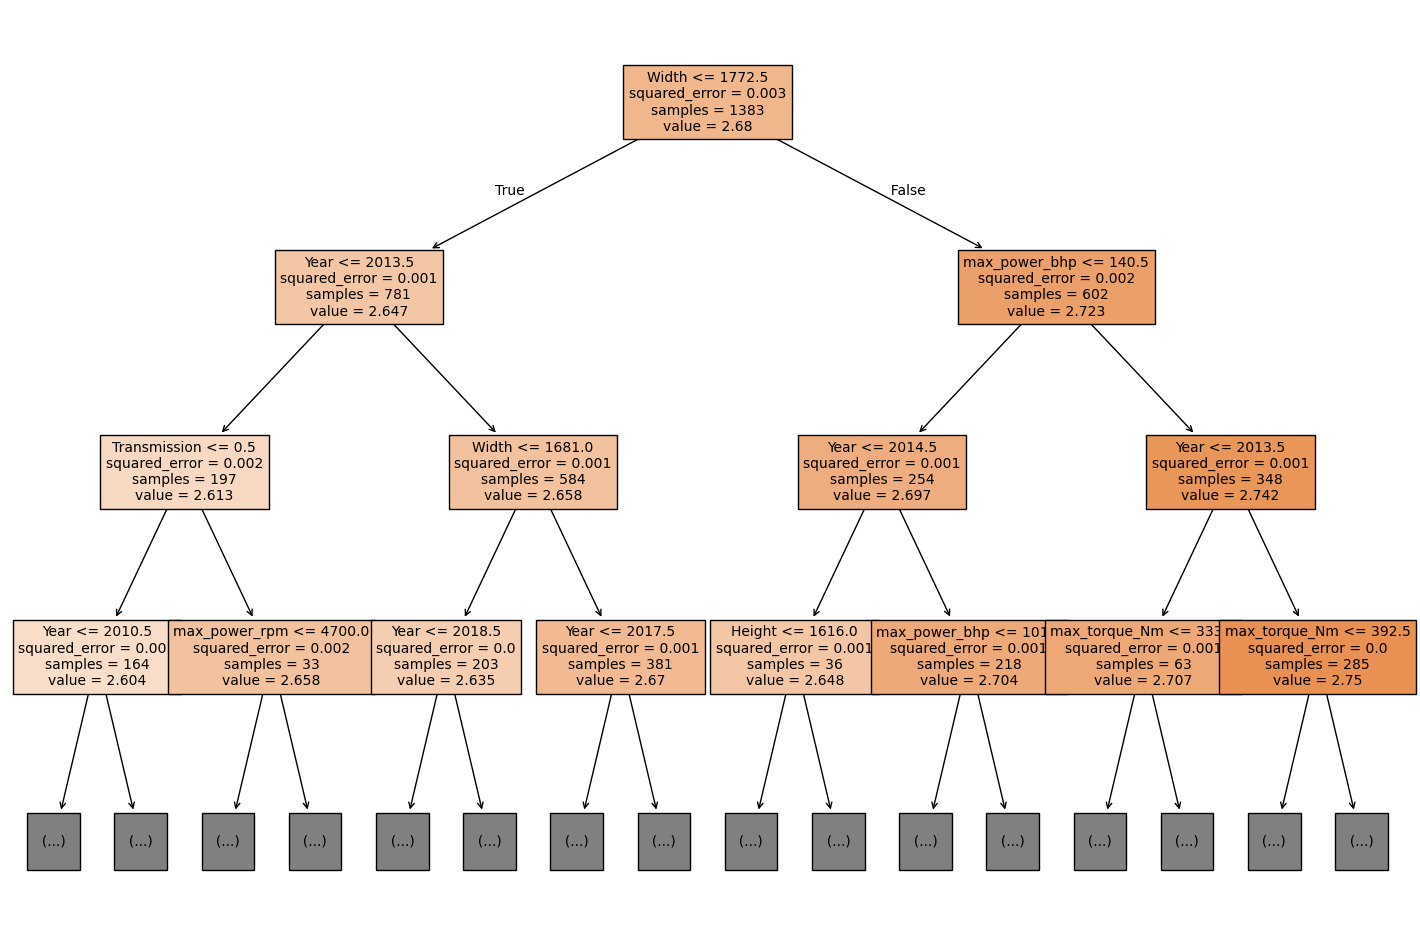

In [117]:
plt.figure(figsize=(18,12))
plot_tree(
    decision_tree=grid.best_estimator_,
    filled=True,# for color
    max_depth=3,             
    fontsize=10,
    feature_names=X_train.columns
)
plt.show()

## Cross Validation

In [118]:
# We need the X and the y ,so we should concat X_train,X_test also y_train,y_test
X_clear = pd.concat([X_train, X_test], axis=0)
y_clear = pd.concat([y_train, y_test], axis=0)
# Do cross validation
scores = cross_val_score(grid.best_estimator_, X_clear, y_clear, cv=5, scoring='r2')
print("Five different trial scores:", scores)
print("Your real R² Score:", scores.mean())

X_clear["Price"] = y_clear
X_clear.to_csv("processed_vehicles_data.csv", index=False)

Five different trial scores: [0.83911762 0.85347114 0.90795744 0.90702677 0.86537648]
Your real R² Score: 0.8745898891503184


In [120]:
# Saving the model to the computer
joblib.dump(model, 'vehicles_price_predict_model.pkl')

['vehicles_price_predict_model.pkl']